# CSC311: training, tuning and model comparison
This notebook executes and presents a fair comparison of **multiclass logistic regression, random forest and a small MLP**, following Appendix B, *Guiding Questions for Methodology*, in `ProjectInstructions/csc311_project_report_template_no_solutions.pdf`.

The separate `CSC311_Project_Instructions.pdf`, section 3.3, asks for a reproducible **planned** methodology at proposal time. These completed experiments provide evidence beyond that minimum. The final-report rubric requires tuning all three families and a metric beyond accuracy.

**Data boundary:** five-fold respondent-grouped cross-validation uses only canonical training responses. The separate validation set is used after tuning to compare three selected configurations. **The local test file is never opened by this experiment.** The saved models are development models fitted on training only; no train-plus-validation refit, test evaluation or submission `pred.py` is produced here.

The existing exploration notebook remains the source for EDA. All modelling results below are computed, not illustrative. Run from the repository root or `analysis/` with the project `.venv` kernel. Model training lives in `analysis/model_experiments.py` so the notebook stays readable and saved models can be reloaded.

In [1]:
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'analysis/model_experiments.py').exists())
sys.path.insert(0,str(ROOT/'analysis'))
from model_experiments import run, provenance, CLASSES, GRIDS, SurveyPreprocessor
OUT=ROOT/'analysis/out/models'
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
def plot_file(name):
    plt.tight_layout()
    plt.savefig(OUT/(name+'.png'),dpi=150,bbox_inches='tight')
    plt.show(); plt.close()
print('Experiment output:',OUT)
display(pd.DataFrame([{'model':f, 'initial grid':str(g)} for f,g in GRIDS.items()]))

Experiment output: c:\vscode\Projects\CSC311_project\analysis\out\models


,model,initial grid
0,softmax,"{'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}"
1,forest,"{'max_depth': [4, 8, 12, None], 'min_samples_l..."
2,mlp,"{'hidden_layer_sizes': [(16,), (32,), (64,)], ..."


## 1. Model families and training choices
- **Softmax regression:** a regularized linear baseline combining evidence from ordinal features, option indicators and sparse words. A linear model may work well even though individual feature histograms overlap.
- **Random forest:** learns thresholds and interactions such as venue × season, while averaging trees. Unlike a single tree it reduces variance, but sparse text and deep trees may still overfit.
- **MLP:** one small ReLU hidden layer tests nonlinear combinations. We restrict capacity because 606 rows come from only 202 people. A large language model would be disproportionate to this sample and deployment constraints.

Softmax uses multinomial cross-entropy, L2 regularization and L-BFGS (`tol=1e-4`, at most 2,000 iterations). The MLP uses cross-entropy, a three-class softmax output, L2 regularization, and L-BFGS with the same tolerance/iteration limit and 50,000 function evaluations. L-BFGS uses no minibatches, learning-rate schedule or validation-based early stopping. Convergence warnings trigger one retry with 10,000 iterations and, for MLP, 200,000 function evaluations; an unresolved warning fails the run rather than silently accepting an unconverged fit.

The forest uses 300 trees, Gini impurity, bootstrap sampling, no class weights, and one CPU thread. Out-of-bag scores are not used: row-level bootstrapping does not keep respondents separate. Tuning seed is 311. BLAS threads are limited to one for controlled runtime; numerical details can still differ across platforms.

## 2. Preprocessing is fitted inside each fold
We reuse the existing encoder's TF-IDF, ordinal, multi-hot and numeric-payment rules, with these modelling additions:

1. Unknown/out-of-range structured responses become missing. Q1–Q4 use training medians; binary multi-hot columns use training modes (ties → 0). An entirely unavailable structured column uses 0. Add a missing flag for each question Q1–Q7.
2. Keep payment mean imputation and the current no-conversion currency assumption. Apply `log1p` after payment imputation. This is now implemented for modelling; the original EDA encoded CSVs remain unchanged.
3. For softmax and MLP, standardize Q1–Q4 and log-payment using training-fold statistics. Leave binary flags and L2-normalized TF-IDF unchanged. Forest uses unstandardized versions of the same information.
4. Learn each vocabulary, IDF, replacement value and scale on the fitting respondents only. Transform the held-out respondents without refitting. Unseen words are ignored. Four separate text caps remain 50/20/50/50, with `min_df=2`.

We do **not** use the precomputed encoded CSVs for cross-validation. Fold feature counts can vary with vocabulary. Within a fold, the fitted transformation is reused across candidate models; this is equivalent to refitting an identical deterministic preprocessing pipeline for each candidate, without the redundant work.

The seven new missing indicators mean the full training representation is expected to have 208 columns rather than the earlier 201. This is verified from fitted artifacts below.

## 3. Execute or verify the experiment
The first run trains every configuration. Later runs reuse completed results **only when the raw training/validation files, encoder, experiment source and package versions match the recorded hashes**. No automatic retuning is performed after validation has been viewed.

To intentionally start a new experiment, use a fresh output directory, for example `python analysis/model_experiments.py --output analysis/out/models_v2`. Do not treat repeated validation-guided changes as an independent holdout estimate. An incomplete run is preserved and must use a fresh output directory to restart.

In [2]:
run(OUT)
manifest=json.loads((OUT/'run_manifest.json').read_text())
assert manifest['status']=='complete'
assert manifest['provenance']==provenance()
assert manifest['test_accessed'] is False
assert manifest['train_validation_refit'] is False
folds=pd.read_csv(OUT/'cv_folds.csv')
summary=pd.read_csv(OUT/'cv_summary.csv')
comparison=pd.read_csv(OUT/'comparison.csv')
selected=json.loads((OUT/'selected_configs.json').read_text())
stability=pd.read_csv(OUT/'seed_stability.csv')
predictions=pd.read_csv(OUT/'validation_predictions.csv')
reports=json.loads((OUT/'classification_reports.json').read_text())
display(pd.Series({k:manifest[k] for k in ['selected_family','cv_configurations','cv_fits','extra_seed_fits','validation_fits','test_accessed']}))
display(pd.Series(manifest['provenance']['packages'],name='version'))

Verified existing completed experiment; no refitting or repeat validation.


selected_family      forest
cv_configurations        44
cv_fits                 220
extra_seed_fits          20
validation_fits           3
test_accessed         False
dtype: object

numpy             2.5.4
pandas            3.1.0
scikit-learn      1.9.1
scipy            1.18.1
joblib            1.6.0
threadpoolctl     3.7.0
Name: version, dtype: str

## 4. Grouped validation and leakage checks
The fixed canonical training partition contains 202 people; each person's three responses stay together. Five shuffled `GroupKFold` folds use seed 311 and identical membership for all models. Class balance follows because every person contributes all three labels. The external validation set contains 44 different respondents.

Cross-validation estimates are used for tuning, not claimed as unbiased final performance. In particular, our feature-engineering choices were informed by exploration of the training set before CV. We therefore retain the untouched local test set for a later final estimate. Ordinary independent-row significance tests would also ignore respondent dependence.

In [3]:
assign=pd.read_csv(OUT/'fold_assignments.csv',dtype={'id':str})
train_meta=pd.read_csv(ROOT/'data/splits/train.csv',usecols=['id','label'],dtype=str)
assert len(assign)==len(train_meta)==606
assert assign.source_row.nunique()==606
assert assign.groupby('id').fold.nunique().eq(1).all()
for fold in sorted(assign.fold.unique()):
    fit_ids=set(assign.loc[assign.fold!=fold,'id'])
    held_ids=set(assign.loc[assign.fold==fold,'id'])
    assert fit_ids.isdisjoint(held_ids)
    labels=train_meta.iloc[assign.loc[assign.fold==fold,'source_row']].label.value_counts()
    assert labels.nunique()==1
assert folds.groupby('config').fold.nunique().eq(5).all()
display(pd.DataFrame(json.loads((OUT/'fold_preprocessing.json').read_text())).drop(columns='tfidf_terms'))
checks=subprocess.run([sys.executable,str(ROOT/'analysis/test_model_preprocessing.py')],capture_output=True,text=True)
print(checks.stdout+checks.stderr)
assert checks.returncode==0
print('PASS: grouped folds, balanced classes, no metadata features and no held-out fitting.')

,fold,train_rows,heldout_rows,train_groups,heldout_groups,features,payment_mean
0,0,483,123,161,41,208,259.414773
1,1,483,123,161,41,208,270.548975
2,2,486,120,162,40,208,300.402552
3,3,486,120,162,40,208,265.645786
4,4,486,120,162,40,208,283.145977


...
----------------------------------------------------------------------
Ran 3 tests in 0.412s

OK

PASS: grouped folds, balanced classes, no metadata features and no held-out fitting.


## 5. Hyperparameter tuning, boundary review and training gaps
Initial grids contain 6 softmax, 24 forest and 12 MLP settings (210 fold fits). Select within each family by **mean CV accuracy**, then mean macro-F1, then lower complexity. Forest simplicity means shallower depth, larger leaves and fewer candidate split features; MLP prefers fewer units, then stronger L2.

Before opening external validation, we expand each selected expandable grid edge by **one step**, varying one parameter at a time around the initial winner: softmax `C` ×10 or ÷10; MLP `alpha` ×10 or ÷10 and hidden width 16→8 or 64→128; forest depth 4→2, leaf size 5→10, or feature fraction 0.5→1.0. Leaf size 1 and unlimited depth are natural limits. This bounded rule checks whether the initial search was too narrow; it does not guarantee a global optimum. The boundary record and actual new fits are shown below.

A high training score paired with a lower CV score indicates overfitting. Smaller `C`, larger MLP `alpha`, and restricted forest depth/leaves are the relevant controls. We do not tune only the apparent winner.

In [4]:
display(pd.DataFrame(json.loads((OUT/'boundary_review.json').read_text())))
for family in ['softmax','forest','mlp']:
    display(Markdown('**'+family+' — all configurations**'))
    view=summary[summary.family==family].sort_values(['cv_accuracy','cv_macro_f1'],ascending=False)
    display(view[['params','stage','train_accuracy','cv_accuracy','cv_accuracy_sd','cv_macro_f1','retries']].round(4))
print('Total optimizer retries in tuning:',int(folds.retry.sum()))
if folds.retry.sum():
    display(folds.loc[folds.retry>0,['family','params','fold','retry','warnings']])

,family,initial_winner,extensions,rule
0,softmax,{'C': 1.0},[],"One step beyond each selected expandable edge,..."
1,forest,"{'max_depth': None, 'max_features': 'sqrt', 'm...",[],"One step beyond each selected expandable edge,..."
2,mlp,"{'alpha': 10.0, 'hidden_layer_sizes': [16]}","[[alpha, 100.0], [hidden_layer_sizes, [8]]]","One step beyond each selected expandable edge,..."


**softmax — all configurations**

,params,stage,train_accuracy,cv_accuracy,cv_accuracy_sd,cv_macro_f1,retries
3,"{""C"": 1.0}",initial,0.9703,0.9043,0.0160,0.9039,0
2,"{""C"": 0.1}",initial,0.9224,0.8977,0.0236,0.8975,0
4,"{""C"": 10.0}",initial,0.9880,0.8846,0.0236,0.8843,0
5,"{""C"": 100.0}",initial,0.9926,0.8666,0.0259,0.8666,0
1,"{""C"": 0.01}",initial,0.8762,0.8630,0.0288,0.8622,0
0,"{""C"": 0.001}",initial,0.8321,0.8067,0.0285,0.8058,0


**forest — all configurations**

,params,stage,train_accuracy,cv_accuracy,cv_accuracy_sd,cv_macro_f1,retries
24,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",initial,0.9934,0.9127,0.0214,0.9125,0
18,"{""max_depth"": 12, ""max_features"": ""sqrt"", ""min...",initial,0.9913,0.9095,0.0319,0.9091,0
20,"{""max_depth"": 12, ""max_features"": ""sqrt"", ""min...",initial,0.9344,0.9061,0.0222,0.9057,0
26,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",initial,0.9356,0.9028,0.0282,0.9024,0
13,"{""max_depth"": 8, ""max_features"": ""sqrt"", ""min_...",initial,0.9402,0.9028,0.0232,0.9024,0
14,"{""max_depth"": 8, ""max_features"": ""sqrt"", ""min_...",initial,0.9286,0.9011,0.0294,0.9007,0
12,"{""max_depth"": 8, ""max_features"": ""sqrt"", ""min_...",initial,0.9625,0.9011,0.0284,0.9003,0
25,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",initial,0.9550,0.8995,0.0279,0.8991,0
19,"{""max_depth"": 12, ""max_features"": ""sqrt"", ""min...",initial,0.9521,0.8978,0.0267,0.8973,0
7,"{""max_depth"": 4, ""max_features"": ""sqrt"", ""min_...",initial,0.9088,0.8978,0.0251,0.8970,0


**mlp — all configurations**

,params,stage,train_accuracy,cv_accuracy,cv_accuracy_sd,cv_macro_f1,retries
39,"{""alpha"": 10.0, ""hidden_layer_sizes"": [16]}",initial,0.9604,0.9010,0.0278,0.9007,0
43,"{""alpha"": 10.0, ""hidden_layer_sizes"": [8]}",boundary_extension,0.9583,0.8993,0.0293,0.8991,0
40,"{""alpha"": 10.0, ""hidden_layer_sizes"": [32]}",initial,0.9583,0.8977,0.0315,0.8974,0
41,"{""alpha"": 10.0, ""hidden_layer_sizes"": [64]}",initial,0.9587,0.8977,0.0315,0.8974,0
36,"{""alpha"": 1.0, ""hidden_layer_sizes"": [16]}",initial,0.9926,0.8928,0.0228,0.8927,1
37,"{""alpha"": 1.0, ""hidden_layer_sizes"": [32]}",initial,0.9934,0.8927,0.0269,0.8925,1
34,"{""alpha"": 0.1, ""hidden_layer_sizes"": [32]}",initial,0.9934,0.8878,0.0277,0.8878,0
35,"{""alpha"": 0.1, ""hidden_layer_sizes"": [64]}",initial,0.9934,0.8846,0.0235,0.8843,0
38,"{""alpha"": 1.0, ""hidden_layer_sizes"": [64]}",initial,0.9934,0.8844,0.0322,0.8843,2
33,"{""alpha"": 0.1, ""hidden_layer_sizes"": [16]}",initial,0.9934,0.8797,0.0280,0.8793,0


Total optimizer retries in tuning: 4


,family,params,fold,retry,warnings
182,mlp,"{""alpha"": 1.0, ""hidden_layer_sizes"": [16]}",2,1,"[""lbfgs failed to converge after 2000 iteratio..."
189,mlp,"{""alpha"": 1.0, ""hidden_layer_sizes"": [32]}",4,1,"[""lbfgs failed to converge after 2000 iteratio..."
190,mlp,"{""alpha"": 1.0, ""hidden_layer_sizes"": [64]}",0,1,"[""lbfgs failed to converge after 2000 iteratio..."
192,mlp,"{""alpha"": 1.0, ""hidden_layer_sizes"": [64]}",2,1,"[""lbfgs failed to converge after 2000 iteratio..."


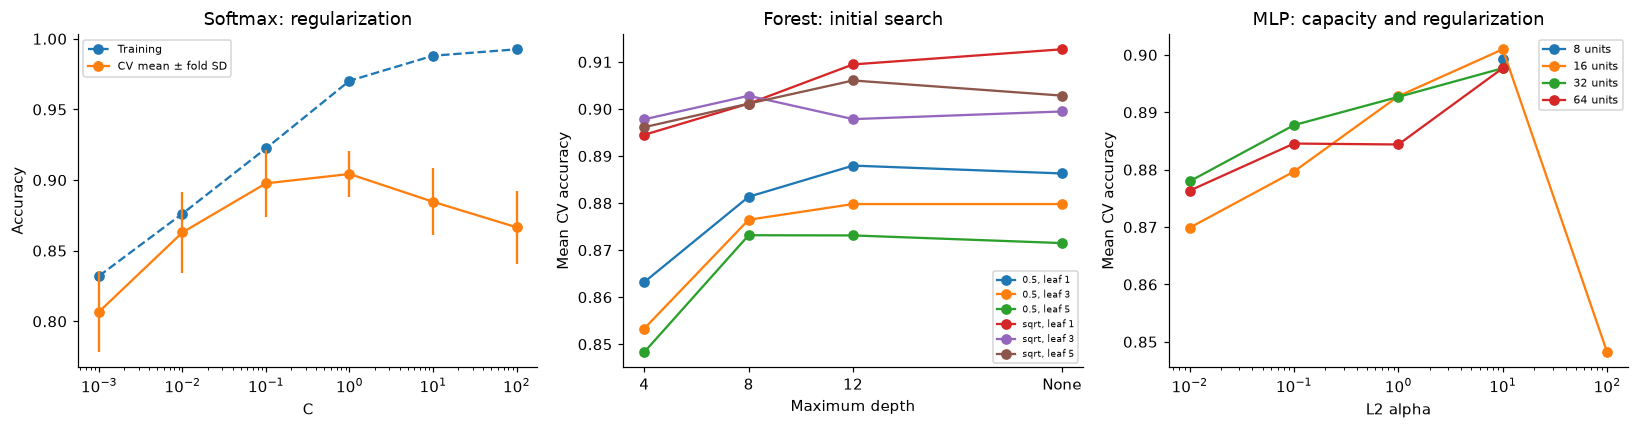

,C,max_depth,max_features,min_samples_leaf,alpha,hidden_layer_sizes
family,,,,,,
softmax,1.0,NaN,NaN,NaN,NaN,NaN
forest,NaN,None,sqrt,1,NaN,NaN
mlp,NaN,NaN,NaN,NaN,10.0,[16]


In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
s=summary[summary.family=='softmax'].copy()
s['C']=s.params.map(lambda p:json.loads(p)['C']); s=s.sort_values('C')
axes[0].plot(s.C,s.train_accuracy,'o--',label='Training')
axes[0].errorbar(s.C,s.cv_accuracy,yerr=s.cv_accuracy_sd,fmt='o-',label='CV mean ± fold SD')
axes[0].set(xscale='log',xlabel='C',ylabel='Accuracy',title='Softmax: regularization'); axes[0].legend(fontsize=7)
s=summary[(summary.family=='forest') & (summary.stage=='initial')].copy()
s['depth']=s.params.map(lambda p:json.loads(p)['max_depth'] or 20)
s['setting']=s.params.map(lambda p:str(json.loads(p)['max_features'])+', leaf '+str(json.loads(p)['min_samples_leaf']))
for setting,g in s.groupby('setting'):
    g=g.sort_values('depth'); axes[1].plot(g.depth,g.cv_accuracy,'o-',label=setting)
axes[1].set(xticks=[4,8,12,20],xticklabels=['4','8','12','None'],xlabel='Maximum depth',ylabel='Mean CV accuracy',title='Forest: initial search')
axes[1].legend(fontsize=6)
s=summary[summary.family=='mlp'].copy()
s['alpha']=s.params.map(lambda p:json.loads(p)['alpha']); s['width']=s.params.map(lambda p:json.loads(p)['hidden_layer_sizes'][0])
for width,g in s.groupby('width'):
    g=g.sort_values('alpha'); axes[2].plot(g.alpha,g.cv_accuracy,'o-',label=str(width)+' units')
axes[2].set(xscale='log',xlabel='L2 alpha',ylabel='Mean CV accuracy',title='MLP: capacity and regularization'); axes[2].legend(fontsize=7)
plot_file('tuning_curves')
display(pd.DataFrame(selected).T.rename_axis('family'))

### What the tuning results show
- **Softmax:** `C=1` gives the highest CV score. Increasing `C` to 10 or 100 raises training accuracy but lowers CV accuracy, consistent with overfitting as regularization weakens.
- **Forest:** 300 trees, unlimited depth, one response per leaf and `max_features="sqrt"` lead CV. Unlimited depth is a natural search boundary; the grid also tested three finite depth limits. The near-perfect training score means we should still monitor generalization, despite the best CV result.
- **MLP:** 16 hidden units with `alpha=10` outperform larger networks in the initial grid. Because width 16 and alpha 10 are search edges, we also test width 8 and alpha 100. Neither improves CV: width 8 reaches about 89.93%, and alpha 100 drops to 84.82%. This supports retaining the selected small, strongly regularized network within our finite search budget.

Four tuning fits triggered convergence-limit retries; all completed after the documented larger optimization budget. Those retries and their original warning messages are saved in `cv_folds.csv`. The selected-family refits had no convergence warnings.

## 6. Seed stability before external validation
The selected forest and MLP settings are rerun over the same five folds using seeds 312 and 313, in addition to 311. These assess sensitivity to sampling/initialization; they are not a search for a lucky seed. Validation refits use the prespecified seed 311. Differences smaller than the fold-to-fold variation are not conclusive. Fold and seed standard deviations are descriptive, not confidence intervals.

In [6]:
seed_summary=stability.groupby(['family','seed']).agg(cv_accuracy=('accuracy','mean'),fold_sd=('accuracy','std'),macro_f1=('macro_f1','mean'),retries=('retry','sum'))
display(seed_summary.round(4))
seed_summary.to_csv(OUT/'seed_summary.csv')
print('Seed-stability optimizer retries:',int(stability.retry.sum()))

cv_accuracy  fold_sd  macro_f1  retries
family seed                                         
forest 311        0.9127   0.0214    0.9125        0
       312        0.9078   0.0185    0.9078        0
       313        0.9143   0.0207    0.9142        0
mlp    311        0.9010   0.0278    0.9007        0
       312        0.8977   0.0315    0.8974        0
       313        0.8993   0.0302    0.8991        0

Seed-stability optimizer retries: 0


## 7. Compare all three tuned families on external validation
Each selected model and its preprocessing is refitted on all 606 training responses, then evaluated on the 132-response validation set. The choice uses validation accuracy, then macro-F1, then a fixed family preference of softmax, forest, MLP for an exact tie. This is a model-selection set, **not an untouched final-test estimate**.

We report accuracy because the assignment scores classification correctness. Macro-F1 averages each sport's F1 equally; per-class precision and recall and confusion matrices reveal failures that accuracy can hide. Weighted F1 instead weights classes by support; with equal class sizes its aggregate matches macro-F1, but macro-F1 states the intended equal-class weighting explicitly. Undefined precision/F1 values use zero. A constant Soccer prediction is the no-skill baseline; its accuracy is 33.3% and macro-F1 is lower.

The course's hidden staff responses may differ culturally from student responses, especially for song/food associations. The chosen validation score cannot establish hidden-test accuracy.

,family,train_accuracy,cv_accuracy,cv_accuracy_sd,cv_macro_f1,validation_accuracy,validation_macro_f1
0,softmax,0.9703,0.9043,0.0160,0.9039,0.9091,0.9089
1,forest,0.9934,0.9127,0.0214,0.9125,0.9318,0.9317
2,mlp,0.9620,0.9010,0.0278,0.9007,0.9091,0.9085


accuracy    0.333333
macro_f1    0.166667
Name: Constant Soccer baseline, dtype: float64

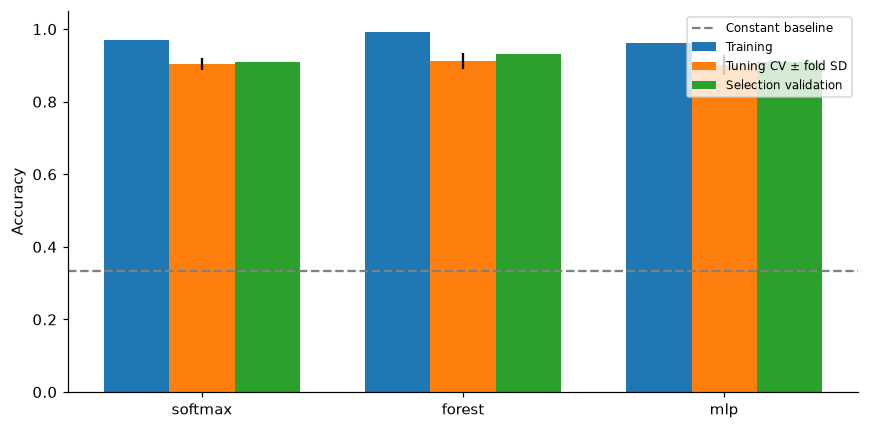

**Selected development family: forest.** Validation accuracy is **93.18%** and macro-F1 **0.9317**. Its tuning-CV accuracy is **91.27% ± 2.14%** (fold SD). This selection is provisional for further project work; it is not a final test result.

softmax: training–CV gap = 6.60%
forest: training–CV gap = 8.07%
mlp: training–CV gap = 6.11%


In [7]:
cols=['family','train_accuracy','cv_accuracy','cv_accuracy_sd','cv_macro_f1','validation_accuracy','validation_macro_f1']
display(comparison[cols].round(4))
display(pd.Series(manifest['baseline'],name='Constant Soccer baseline'))
fig,ax=plt.subplots(figsize=(8,4))
x=np.arange(len(comparison)); w=.25
ax.bar(x-w,comparison.train_accuracy,w,label='Training')
ax.bar(x,comparison.cv_accuracy,w,yerr=comparison.cv_accuracy_sd,label='Tuning CV ± fold SD')
ax.bar(x+w,comparison.validation_accuracy,w,label='Selection validation')
ax.axhline(1/3,color='gray',linestyle='--',label='Constant baseline')
ax.set(xticks=x,xticklabels=comparison.family,ylabel='Accuracy',ylim=(0,1.05)); ax.legend(fontsize=8)
plot_file('model_comparison')
winner=manifest['selected_family']; row=comparison.set_index('family').loc[winner]
display(Markdown(f'**Selected development family: {winner}.** Validation accuracy is **{row.validation_accuracy:.2%}** and macro-F1 **{row.validation_macro_f1:.4f}**. Its tuning-CV accuracy is **{row.cv_accuracy:.2%} ± {row.cv_accuracy_sd:.2%}** (fold SD). This selection is provisional for further project work; it is not a final test result.'))
for _,r in comparison.iterrows():
    print(f"{r.family}: training–CV gap = {r.train_accuracy-r.cv_accuracy:.2%}")

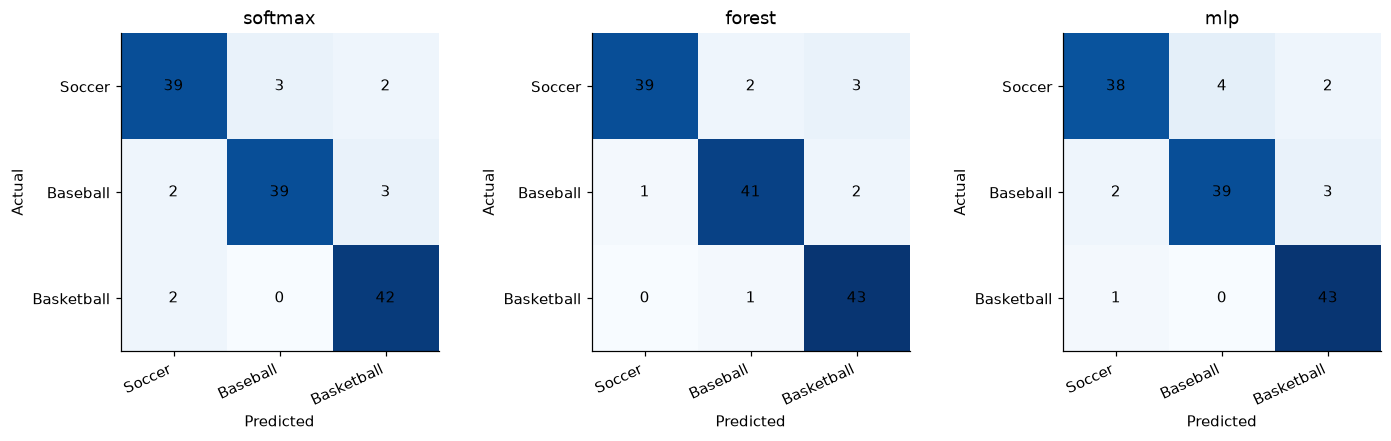

**softmax per-class validation metrics**

,precision,recall,f1-score,support
Soccer,0.9070,0.8864,0.8966,44.0
Baseball,0.9286,0.8864,0.9070,44.0
Basketball,0.8936,0.9545,0.9231,44.0


**forest per-class validation metrics**

,precision,recall,f1-score,support
Soccer,0.9750,0.8864,0.9286,44.0
Baseball,0.9318,0.9318,0.9318,44.0
Basketball,0.8958,0.9773,0.9348,44.0


**mlp per-class validation metrics**

,precision,recall,f1-score,support
Soccer,0.9268,0.8636,0.8941,44.0
Baseball,0.9070,0.8864,0.8966,44.0
Basketball,0.8958,0.9773,0.9348,44.0


errors
actual     predicted         
Baseball   Basketball       2
           Soccer           1
Basketball Baseball         1
Soccer     Baseball         2
           Basketball       3

,source_row,id,actual,predicted
148,16,52,Baseball,Basketball
156,24,71,Soccer,Baseball
165,33,91,Soccer,Basketball
187,55,140,Baseball,Soccer
201,69,163,Soccer,Baseball
203,71,163,Basketball,Baseball
213,81,180,Soccer,Basketball
225,93,204,Soccer,Basketball
232,100,216,Baseball,Basketball


Errors are listed without reading validation feature text to redesign features.


In [8]:
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,family in zip(axes,['softmax','forest','mlp']):
    cm=pd.read_csv(OUT/f'{family}_confusion.csv',index_col=0)
    ax.imshow(cm.to_numpy(),cmap='Blues',vmin=0,vmax=44)
    for i in range(3):
        for j in range(3): ax.text(j,i,str(cm.iloc[i,j]),ha='center',va='center')
    ax.set(xticks=range(3),xticklabels=CLASSES,yticks=range(3),yticklabels=CLASSES,title=family,xlabel='Predicted',ylabel='Actual')
    plt.setp(ax.get_xticklabels(),rotation=25,ha='right')
plot_file('validation_confusions')
for family in ['softmax','forest','mlp']:
    display(Markdown('**'+family+' per-class validation metrics**'))
    display(pd.DataFrame(reports[family]).T.loc[CLASSES,['precision','recall','f1-score','support']].round(4))
errors=predictions[(predictions.family==winner) & (predictions.actual!=predictions.predicted)]
display(errors.groupby(['actual','predicted']).size().rename('errors').to_frame())
display(errors[['source_row','id','actual','predicted']])
print('Errors are listed without reading validation feature text to redesign features.')

## 8. Deployment checks and what remains
The saved `.joblib` files are development artifacts and require scikit-learn; they are **not** valid final `pred.py` submissions. We check that a reloaded artifact reproduces stored validation predictions. Do not load pickle/joblib files from untrusted sources.

After the team freezes model and preprocessing choices, refitting on training plus validation will add 44 respondents but remove validation as an independent check. The still-untouched local test set then provides a one-time evaluation. This notebook deliberately stops before that step so methodology can still be discussed without spending the final holdout.

Final inference must export parameters and preprocessing and run with standard library/NumPy/pandas only. Logistic regression uses a linear score; an MLP uses matrix products and ReLU; a forest traverses nodes and averages probabilities. A later implementation must verify equivalence, total submission size ≤10 MB and about 60 predictions within one minute. Current artifact sizes below are informative, not proof of submission compliance.

In [9]:
import joblib
val=pd.read_csv(ROOT/'data/splits/val.csv',dtype=str,keep_default_na=False)
sizes=[]
for family in ['softmax','forest','mlp']:
    path=OUT/f'{family}_development.joblib'
    artifact=joblib.load(path)
    predicted=artifact['model'].predict(artifact['preprocessor'].transform(val,artifact['scaled']))
    recorded=predictions[predictions.family==family].sort_values('source_row').predicted.to_numpy()
    np.testing.assert_array_equal(predicted,recorded)
    sizes.append({'family':family,'artifact_bytes':path.stat().st_size,'features':len(artifact['preprocessor'].columns_)})
display(pd.DataFrame(sizes))
print('PASS: saved artifacts reproduce stored validation predictions. No test data read.')

,family,artifact_bytes,features
0,softmax,23383,208
1,forest,6443472,208
2,mlp,79129,208


PASS: saved artifacts reproduce stored validation predictions. No test data read.
